# Introduction to Machine Learning – Lab 2
## Comparison of Data Preparation Strategies

### Objective
Notebook 02 evaluated the XGBoost classifier with one data preparation setup. This notebook repeats all of its experiments for different data preparation strategies and compares the results. Starting from the setup of notebook 02 (the **baseline**), every variant changes exactly one thing; the variants are listed in Section 1.

### Experiments Conducted
For every variant, the same experiments as in notebook 02, with the default XGBoost model:
1. **Holdout split:** 10% and 20% test set, each with and without stratification, for 10 split seeds each (40 splits).
2. **k-fold cross-validation:** $k=5$ and $k=10$, each with `KFold` and `StratifiedKFold` (30 folds).

**Paired comparison:** all splits are drawn once, on the 2,925 houses of the baseline, and every variant is fitted and scored on exactly the same splits. Differences between variants therefore never come from different test houses. In the variant that keeps the extreme houses, these 5 houses are added to the training part of every split, but never used as test houses.

**Metrics:** accuracy and macro-F1 (main metric, as in notebook 02).

Running all experiments takes about 25 minutes (9 variants × 70 fitted models).

### 1. Data and variants

In [1]:
import sys
from pathlib import Path

# Add project root and notebooks/ to system path
sys.path.append(str(Path(".").resolve()))
sys.path.append(str(Path("notebooks").resolve()))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from evaluation import evaluate, make_splits, paired_differences, summarize
from preprocessing import EXTREME_AREA, NEAR_CONSTANT, REDUNDANT, build_pipeline, load_raw, prepare_data

DATA_PATH = Path("../data/AmesHousing.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("data/AmesHousing.csv")

# All 2,930 houses; the experiments only test on the houses up to 4,000 ft² living area
X, y = prepare_data(DATA_PATH)
raw = load_raw(DATA_PATH)
normal_houses = X.index[X["Gr Liv Area"] <= EXTREME_AREA]
extreme_houses = X.index[X["Gr Liv Area"] > EXTREME_AREA]

print(f"{len(normal_houses):,} houses up to {EXTREME_AREA:,} ft², {len(extreme_houses)} extreme houses:")
display(raw.loc[extreme_houses, ["Gr Liv Area", "SalePrice", "Sale Condition"]])

2,925 houses up to 4,000 ft², 5 extreme houses:


,Gr Liv Area,SalePrice,Sale Condition
1498,5642,160000,Partial
1760,4476,745000,Abnorml
1767,4316,755000,Normal
2180,5095,183850,Partial
2181,4676,184750,Partial


In [2]:
# Share of the most frequent value of each nearly constant feature (raw values)
near_constant = pd.DataFrame(
    {
        "Most Frequent Value": [raw[col].mode()[0] for col in NEAR_CONSTANT],
        "Share (%)": [raw[col].value_counts(normalize=True).iloc[0] * 100 for col in NEAR_CONSTANT],
    },
    index=NEAR_CONSTANT,
).round(2)
display(near_constant)


def similarity(dropped, kept):
    """How closely a redundant feature follows the feature that is kept instead."""
    if isinstance(X[dropped].dtype, pd.CategoricalDtype):
        same = (X[dropped].astype(str) == X[kept].astype(str)).mean()
        return f"same value for {same:.0%} of the houses"
    return f"Spearman r = {X[dropped].corr(X[kept], method='spearman'):.2f}"


redundant = pd.DataFrame(
    [{"Dropped": dropped, "Kept": kept, "Similarity": similarity(dropped, kept)} for dropped, kept in REDUNDANT.items()]
)
display(redundant)

,Most Frequent Value,Share (%)
Utilities,AllPub,99.90
Street,Pave,99.59
Condition 2,Norm,98.98
Roof Matl,CompShg,98.53
Heating,GasA,98.46
Pool QC,NA,99.56
Misc Feature,NA,96.38


,Dropped,Kept,Similarity
0,Garage Yr Blt,Year Built,Spearman r = 0.90
1,Garage Cars,Garage Area,Spearman r = 0.86
2,TotRms AbvGrd,Gr Liv Area,Spearman r = 0.81
3,1st Flr SF,Total Bsmt SF,Spearman r = 0.83
4,Exterior 2nd,Exterior 1st,same value for 85% of the houses


* **Extreme houses:** three of the five houses above 4,000 ft² are partial sales (houses not yet finished when sold) for only \$160,000–\$184,750, far below what their size suggests. The other two sold for \$745,000 and \$755,000. The documentation of the dataset recommends removing these five houses.
* **Nearly constant features:** for all seven, 96.4–99.9% of the houses share the same value, so each of them can only separate a handful of houses.
* **Redundant features:** each dropped feature measures almost the same thing as the feature kept instead (Spearman $r$ = 0.81–0.90; Exterior 2nd equals Exterior 1st for 85% of the houses). 1st Flr SF even follows exactly from Gr Liv Area − 2nd Flr SF − Low Qual Fin SF.

In [3]:
def variant(name, change, strategy="onehot", keep_extreme=False, **data_options):
    """One data preparation variant: the baseline with one change."""
    return {
        "Variant": name,
        "Change": change,
        "strategy": strategy,
        "keep_extreme": keep_extreme,
        "data_options": {"drop_near_constant": True, **data_options},
    }


VARIANTS = [
    variant("Baseline", "Setup of notebook 02: one-hot encoding, no nearly constant features, no extreme houses"),
    variant("Keep nearly constant", "The 7 nearly constant features stay in the data", drop_near_constant=False),
    variant("Keep extreme houses", "The 5 extreme houses are added to the training part of every split", keep_extreme=True),
    variant("Ordinal encoding", "Nominal features as one integer per category", strategy="ordinal"),
    variant("Target encoding", "Nominal features as the smoothed share of each price class per category", strategy="target"),
    variant("Native categories", "Nominal features handled by XGBoost itself", strategy="native"),
    variant("Size totals", "Adds Total SF, Total Bathrooms and Total Porch SF", add_size_totals=True),
    variant("Ages", "Adds Age At Sale and Years Since Remod", add_age_features=True),
    variant("Without redundant", "Drops the 5 redundant features listed above", drop_redundant=True),
]
BASELINE = VARIANTS[0]["Variant"]

# Features and price classes of each variant, for all 2,930 houses (the splits pick the houses)
data = {v["Variant"]: prepare_data(DATA_PATH, **v["data_options"]) for v in VARIANTS}

display(
    pd.DataFrame(
        [{"Variant": v["Variant"], "Change": v["Change"], "Features": data[v["Variant"]][0].shape[1]} for v in VARIANTS]
    ).set_index("Variant")
)

,Change,Features
Variant,,
Baseline,"Setup of notebook 02: one-hot encoding, no nea...",72
Keep nearly constant,The 7 nearly constant features stay in the data,79
Keep extreme houses,The 5 extreme houses are added to the training...,72
Ordinal encoding,Nominal features as one integer per category,72
Target encoding,Nominal features as the smoothed share of each...,72
Native categories,Nominal features handled by XGBoost itself,72
Size totals,"Adds Total SF, Total Bathrooms and Total Porch SF",75
Ages,Adds Age At Sale and Years Since Remod,74
Without redundant,Drops the 5 redundant features listed above,67


### 2. Running the experiments
The splits are drawn once on the 2,925 houses of the baseline: 40 holdout splits (4 setups × 10 seeds) and 30 cross-validation folds (5 + 5 + 10 + 10). Every variant is fitted and scored on all 70 of them.

In [4]:
splits = make_splits(y.loc[normal_houses])

results = []
for v in VARIANTS:
    X_v, y_v = data[v["Variant"]]
    extra_train = extreme_houses if v["keep_extreme"] else None
    scores = evaluate(build_pipeline(v["strategy"]), X_v, y_v, splits, extra_train=extra_train)
    results.append(scores.assign(Variant=v["Variant"]))
    print(f"{v['Variant']}: done")

results = pd.concat(results, ignore_index=True)
print(f"{len(splits)} splits × {len(VARIANTS)} variants = {len(results)} fitted models")

Baseline: done
Keep nearly constant: done
Keep extreme houses: done
Ordinal encoding: done
Target encoding: done
Native categories: done
Size totals: done
Ages: done
Without redundant: done
70 splits × 9 variants = 630 fitted models


### 3. Results per variant
Mean ± standard deviation over the 10 seeds (holdout) or the $k$ folds (cross-validation). The standard deviation is the sample standard deviation, so the cross-validation values are slightly larger than in notebook 02, which used the population standard deviation; the means of the baseline are identical to notebook 02.

In [5]:
print("Test macro-F1")
display(summarize(results, "Test Macro-F1"))

print("Test accuracy")
display(summarize(results, "Test Accuracy"))

Test macro-F1


Setup,Holdout 10%,"Holdout 10%, stratified",Holdout 20%,"Holdout 20%, stratified",CV k=5,"CV k=5, stratified",CV k=10,"CV k=10, stratified"
Variant,,,,,,,,
Baseline,0.7486 ± 0.0238,0.7596 ± 0.0342,0.7357 ± 0.0172,0.7546 ± 0.0245,0.7421 ± 0.0286,0.7494 ± 0.0236,0.7574 ± 0.0252,0.7546 ± 0.0432
Keep nearly constant,0.7497 ± 0.0296,0.7565 ± 0.0323,0.7361 ± 0.0197,0.7495 ± 0.0247,0.7408 ± 0.0244,0.7471 ± 0.0325,0.7438 ± 0.0183,0.7482 ± 0.0454
Keep extreme houses,0.7435 ± 0.0188,0.7606 ± 0.0369,0.7365 ± 0.0173,0.7474 ± 0.0219,0.7397 ± 0.0186,0.7440 ± 0.0290,0.7504 ± 0.0327,0.7478 ± 0.0353
Ordinal encoding,0.7476 ± 0.0263,0.7548 ± 0.0356,0.7297 ± 0.0247,0.7456 ± 0.0231,0.7359 ± 0.0238,0.7397 ± 0.0303,0.7381 ± 0.0220,0.7464 ± 0.0391
Target encoding,0.7459 ± 0.0269,0.7422 ± 0.0514,0.7322 ± 0.0302,0.7502 ± 0.0233,0.7306 ± 0.0326,0.7425 ± 0.0291,0.7429 ± 0.0265,0.7399 ± 0.0374
Native categories,0.7430 ± 0.0346,0.7491 ± 0.0411,0.7356 ± 0.0181,0.7558 ± 0.0253,0.7429 ± 0.0272,0.7392 ± 0.0306,0.7431 ± 0.0252,0.7315 ± 0.0408
Size totals,0.7587 ± 0.0362,0.7599 ± 0.0298,0.7484 ± 0.0255,0.7503 ± 0.0239,0.7486 ± 0.0112,0.7491 ± 0.0178,0.7365 ± 0.0171,0.7442 ± 0.0315
Ages,0.7458 ± 0.0265,0.7536 ± 0.0391,0.7342 ± 0.0198,0.7515 ± 0.0258,0.7368 ± 0.0221,0.7456 ± 0.0264,0.7532 ± 0.0208,0.7533 ± 0.0414
Without redundant,0.7521 ± 0.0276,0.7486 ± 0.0366,0.7398 ± 0.0189,0.7546 ± 0.0270,0.7434 ± 0.0296,0.7424 ± 0.0259,0.7453 ± 0.0238,0.7421 ± 0.0396


Test accuracy


Setup,Holdout 10%,"Holdout 10%, stratified",Holdout 20%,"Holdout 20%, stratified",CV k=5,"CV k=5, stratified",CV k=10,"CV k=10, stratified"
Variant,,,,,,,,
Baseline,0.7546 ± 0.0198,0.7689 ± 0.0311,0.7547 ± 0.0121,0.7615 ± 0.0176,0.7542 ± 0.0235,0.7641 ± 0.0215,0.7648 ± 0.0212,0.7665 ± 0.0329
Keep nearly constant,0.7567 ± 0.0217,0.7621 ± 0.0207,0.7538 ± 0.0113,0.7569 ± 0.0164,0.7494 ± 0.0222,0.7672 ± 0.0270,0.7573 ± 0.0179,0.7658 ± 0.0334
Keep extreme houses,0.7488 ± 0.0205,0.7655 ± 0.0299,0.7515 ± 0.0119,0.7617 ± 0.0150,0.7494 ± 0.0218,0.7651 ± 0.0262,0.7600 ± 0.0235,0.7589 ± 0.0320
Ordinal encoding,0.7625 ± 0.0201,0.7601 ± 0.0226,0.7489 ± 0.0161,0.7590 ± 0.0147,0.7484 ± 0.0179,0.7634 ± 0.0257,0.7494 ± 0.0210,0.7596 ± 0.0274
Target encoding,0.7601 ± 0.0278,0.7590 ± 0.0260,0.7487 ± 0.0197,0.7595 ± 0.0189,0.7446 ± 0.0219,0.7600 ± 0.0244,0.7532 ± 0.0226,0.7552 ± 0.0406
Native categories,0.7587 ± 0.0308,0.7635 ± 0.0294,0.7526 ± 0.0177,0.7643 ± 0.0189,0.7545 ± 0.0219,0.7573 ± 0.0368,0.7535 ± 0.0254,0.7535 ± 0.0323
Size totals,0.7584 ± 0.0212,0.7648 ± 0.0237,0.7550 ± 0.0179,0.7603 ± 0.0179,0.7549 ± 0.0186,0.7600 ± 0.0204,0.7562 ± 0.0217,0.7627 ± 0.0320
Ages,0.7553 ± 0.0223,0.7659 ± 0.0253,0.7491 ± 0.0138,0.7622 ± 0.0188,0.7528 ± 0.0149,0.7648 ± 0.0221,0.7597 ± 0.0241,0.7644 ± 0.0334
Without redundant,0.7608 ± 0.0214,0.7628 ± 0.0259,0.7530 ± 0.0131,0.7662 ± 0.0170,0.7556 ± 0.0292,0.7641 ± 0.0167,0.7607 ± 0.0219,0.7607 ± 0.0285


In [6]:
# Training vs. test scores per variant, averaged over all 70 splits
gap = results.groupby("Variant", sort=False)[["Train Macro-F1", "Test Macro-F1"]].mean()
gap["Gap"] = gap["Train Macro-F1"] - gap["Test Macro-F1"]
display(gap.round(4))

,Train Macro-F1,Test Macro-F1,Gap
Variant,,,
Baseline,1.0000,0.7509,0.2491
Keep nearly constant,1.0000,0.7468,0.2532
Keep extreme houses,1.0000,0.7469,0.2531
Ordinal encoding,1.0000,0.7429,0.2571
Target encoding,0.9911,0.7414,0.2497
Native categories,1.0000,0.7427,0.2573
Size totals,1.0000,0.7495,0.2505
Ages,1.0000,0.7476,0.2524
Without redundant,1.0000,0.7465,0.2535


#### Interpretation of the results per variant
* **All variants are close.** The mean test macro-F1 of every variant lies between 0.730 and 0.761 in every setup. Within one setup, the variants differ by at most 0.023, which is about as large as or smaller than the standard deviation over the splits (0.011–0.051).
* **No variant wins consistently.** The best variant changes from setup to setup: the baseline is best in three setups (all cross-validation), Size totals in three others (both holdout splits without stratification and CV $k=5$), but Size totals is also the worst variant with 10-fold cross-validation (0.737 vs. 0.757 for the baseline). Comparing means alone cannot settle this, which is why Section 4 compares the variants split by split.
* **Same overfitting for every variant.** All variants fit the training houses perfectly (training macro-F1 1.0), and the gap to the test macro-F1 is 0.249–0.257 for all of them. The data preparation does not change the high variance found in notebook 02. The one exception, target encoding with a training macro-F1 of 0.991, is a side effect of the encoder: during fitting it encodes the training houses with internal cross-fitting, during prediction with the encoder fitted on all training houses, so the model sees slightly different values for the same houses.

### 4. Paired differences to the baseline
For every split: the macro-F1 of a variant minus the macro-F1 of the baseline on the same split (positive = better than the baseline). Both are scored on the same test houses, so an easy or hard test set affects both scores in the same way. This shows how often a variant beats the baseline, which the mean ± standard deviation tables above cannot answer.

In [7]:
differences = paired_differences(results, BASELINE)
experiment = differences.index.get_level_values("Setup").str.split().str[0]  # "Holdout" or "CV"


def describe(diffs):
    """Mean and spread of the paired differences, and on how many splits the variant is better or worse."""
    return pd.DataFrame(
        {
            "Mean Difference": diffs.mean(),
            "Std": diffs.std(),
            "Better": (diffs > 0).sum(),
            "Worse": (diffs < 0).sum(),
        }
    )


groups = {name: describe(group) for name, group in differences.groupby(experiment, sort=False)}
groups["All 70 splits"] = describe(differences)
display(pd.concat(groups, axis=1).round(4))

Holdout                                   CV  \
                     Mean Difference     Std Better Worse Mean Difference   
Variant                                                                     
Keep nearly constant         -0.0017  0.0121     19    21         -0.0073   
Keep extreme houses          -0.0026  0.0142     16    24         -0.0059   
Ordinal encoding             -0.0052  0.0198     13    27         -0.0118   
Target encoding              -0.0070  0.0249     13    27         -0.0128   
Native categories            -0.0038  0.0161     16    24         -0.0140   
Size totals                   0.0047  0.0253     21    19         -0.0094   
Ages                         -0.0033  0.0178     18    22         -0.0033   
Without redundant            -0.0009  0.0173     21    19         -0.0091   

                                            All 70 splits                       
                         Std Better Worse Mean Difference     Std Better Worse  
Variant                                                                         
Keep nearly constant  0.0150      9    21         -0.0041  0.0136     28    42  
Keep extreme houses   0.0170     13    17         -0.0040  0.0154     29    41  
Ordinal encoding      0.0193      7    23         -0.0080  0.0197     20    50  
Target encoding       0.0182      9    21         -0.0095  0.0223     22    48  
Native categories     0.0212     11    19         -0.0082  0.0190     27    43  
Size totals           0.0251     10    20         -0.0014  0.0260     31    39  
Ages                  0.0173     14    16         -0.0033  0.0174     32    38  
Without redundant     0.0153      7    23         -0.0044  0.0169     28    42

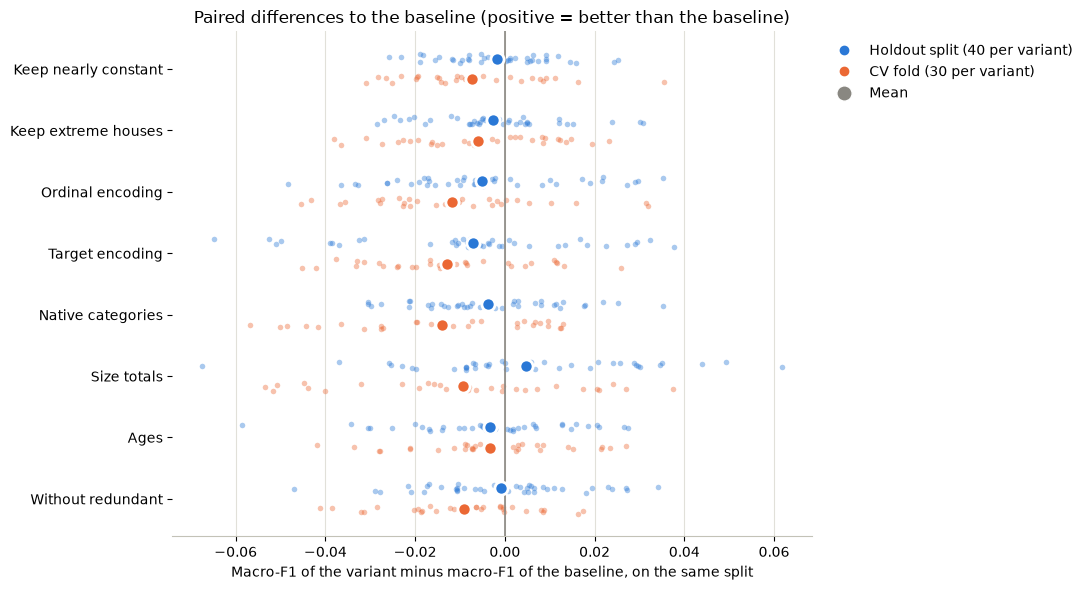

In [8]:
# One small dot per split, one large dot for the mean, per variant and experiment type
COLORS = {"Holdout": "#2a78d6", "CV": "#eb6834"}
LABELS = {"Holdout": "Holdout split", "CV": "CV fold"}
MUTED, GRID, AXIS = "#898781", "#e1e0d9", "#c3c2b7"
rng = np.random.default_rng(0)

fig, ax = plt.subplots(figsize=(11, 6))
for row, name in enumerate(differences.columns):
    for offset, (exp, color) in zip((-0.17, 0.17), COLORS.items()):
        values = differences.loc[experiment == exp, name]
        jitter = rng.uniform(-0.07, 0.07, len(values))
        ax.scatter(values, row + offset + jitter, s=16, color=color, alpha=0.4, linewidths=0)
        ax.scatter(values.mean(), row + offset, s=90, color=color, edgecolors="white", linewidths=2, zorder=3)

ax.axvline(0, color=MUTED, linewidth=1.2)
ax.set_yticks(range(len(differences.columns)), differences.columns)
ax.invert_yaxis()
ax.set_xlabel("Macro-F1 of the variant minus macro-F1 of the baseline, on the same split")
ax.set_title("Paired differences to the baseline (positive = better than the baseline)", fontsize=12)
ax.grid(axis="x", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(AXIS)

handles = [
    Line2D([], [], marker="o", linestyle="", color=color, markersize=6, label=f"{LABELS[exp]} ({(experiment == exp).sum()} per variant)")
    for exp, color in COLORS.items()
]
handles.append(Line2D([], [], marker="o", linestyle="", color=MUTED, markeredgecolor="white", markersize=11, label="Mean"))
ax.legend(handles=handles, frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))

plt.tight_layout()
plt.show()

#### Interpretation of the paired differences
* **No change improves on the baseline.** Over all 70 splits, the mean difference is negative for every variant (−0.0014 to −0.0095), and every variant is worse than the baseline on more splits than it is better. In the plot, all means lie at or left of zero, while the single splits scatter by up to about ±0.06 on both sides.
* **Other encodings (largest losses):** target encoding −0.0095 (worse on 48 of 70 splits), native categories −0.0082 (43 of 70), ordinal encoding −0.0080 (50 of 70). Possible explanations:
  * *Ordinal:* the integers follow the alphabetical order of the categories, which means nothing for the price. A tree needs several splits to isolate a single category (e.g. one neighborhood) and groups unrelated categories along the way.
  * *Native:* XGBoost searches for the best grouping of the categories at every split. With many categories (e.g. 28 neighborhoods) this is very flexible and fits the training houses even more closely.
  * *Target:* six columns per feature with the price-class shares of each category. For rare categories, these shares rest on a few houses and are noisy.
* **Nearly constant features and extreme houses (small losses):** keeping the nearly constant features costs −0.0041 (worse on 42 of 70), training on the extreme houses −0.0040 (41 of 70). Both fit the expectation: the nearly constant features can only separate a handful of houses, which mostly fits noise, and the three partial sales teach the trees that very large houses can be cheap.
* **Without redundant features (small loss):** −0.0044 (worse on 42 of 70). The dropped features are similar to the kept ones ($r$ = 0.81–0.90), but not identical, so a little information is lost.
* **New features (smallest differences):** Size totals −0.0014 (better on 31 of 70; better on the holdout splits with +0.0047, worse in cross-validation with −0.0094), Ages −0.0033 (better on 32 of 70). Ages adds almost nothing new: all houses were sold between 2006 and 2010, so Age At Sale is practically Year Built reversed ($r$ = −0.999), and the trees could already split on Year Built. Total SF follows Gr Liv Area closely (Spearman $r$ = 0.86), and the trees already combine the size features over several splits.
* **How certain is this?** All mean differences are below 0.01 macro-F1, inside the spread of the single splits (standard deviation 0.012–0.026). The counts are consistent (e.g. ordinal worse on 50 of 70 splits), but the 70 splits overlap: the CV folds and the holdout seeds share most of their training houses, so they are not 70 independent tests. The safe reading: no variant is better than the baseline, and the encodings other than one-hot are probably slightly worse.

### 5. Conclusion
* With the default model, none of the eight changes improves on the baseline of notebook 02. All differences are below 0.01 macro-F1, small compared with the spread over the splits.
* The train-test gap of about 0.25 is the same for every variant, so the main problem is the overfitting of the model, not the data preparation. Regularizing the model through its hyperparameters promises more than further data preparation.
* The following experiments therefore keep the baseline: one-hot encoding, without the nearly constant features and without the 5 extreme houses.
* Two variants are worth checking again once the model is tuned: Size totals, the only variant that beats the baseline on the holdout splits on average (+0.0047), and Without redundant, which costs only 0.004 macro-F1 but has 5 fewer features, so the feature importance is not split between near-duplicates.